<a href="https://colab.research.google.com/github/salimkhaskhoussy/deep-learning-projects/blob/main/TomatoGuard_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()


Saving archive.zip to archive.zip


In [2]:
!unzip -q archive.zip -d /content/tomato_data


In [3]:
import os

for root, dirs, files in os.walk('/content/tomato_data'):
    level = root.replace('/content/tomato_data', '').count(os.sep)
    if level < 3:
        print('  ' * level + os.path.basename(root) + '/')


tomato_data/
  New Plant Diseases Dataset(Augmented)/
    train/
    valid/
  new plant diseases dataset(augmented)/
    New Plant Diseases Dataset(Augmented)/


### 1. Définition des chemins et chargement des données
Nous allons configurer le chargement automatique de nos ensembles de données d'entraînement et de validation en utilisant TensorFlow et Keras.

In [4]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Chemins vers les répertoires d'entraînement et de validation
train_dir = '/content/tomato_data/New Plant Diseases Dataset(Augmented)/train'
val_dir = '/content/tomato_data/New Plant Diseases Dataset(Augmented)/valid'

# Paramètres globaux
BATCH_SIZE = 32
IMG_SIZE = (128, 128)

# Prétraitement et normalisation des images [0, 1]
train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

val_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical'
)

# Récupérer le nombre de classes
num_classes = len(train_generator.class_indices)
print(f"Nombre de classes détectées : {num_classes}")

Found 18345 images belonging to 10 classes.
Found 4585 images belonging to 10 classes.
Nombre de classes détectées : 10


### 2. Construction du modèle CNN
Création d'une architecture CNN robuste avec des couches `Conv2D`, `MaxPooling2D`, `Dropout` pour régulariser, et `Dense` pour la classification.

In [5]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

model = Sequential([
    # Premier bloc convolutif
    Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    MaxPooling2D(2, 2),

    # Deuxième bloc convolutif
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Troisième bloc convolutif
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D(2, 2),

    # Flatten pour passer aux couches denses
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),

    # Couche de sortie
    Dense(num_classes, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,930 (12.61 MB)

 Trainable params: 3,305,930 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### 3. Entraînement du modèle CNN
Nous allons lancer l'entraînement pour 10 époques (vous pouvez ajuster ce nombre pour de meilleurs résultats).

In [6]:
epochs = 10

history = model.fit(
    train_generator,
    epochs=epochs,
    validation_data=val_generator
)

Epoch 1/10
574/574 ━━━━━━━━━━━━━━━━━━━━ 741s 1s/step - accuracy: 0.5248 - loss: 1.3420 - val_accuracy: 0.7610 - val_loss: 0.6903
Epoch 2/10
574/574 ━━━━━━━━━━━━━━━━━━━━ 831s 1s/step - accuracy: 0.7340 - loss: 0.7759 - val_accuracy: 0.8246 - val_loss: 0.5205
Epoch 3/10
574/574 ━━━━━━━━━━━━━━━━━━━━ 846s 1s/step - accuracy: 0.7958 - loss: 0.5927 - val_accuracy: 0.8504 - val_loss: 0.4259
Epoch 4/10
574/574 ━━━━━━━━━━━━━━━━━━━━ 816s 1s/step - accuracy: 0.8353 - loss: 0.4809 - val_accuracy: 0.8809 - val_loss: 0.3513
Epoch 5/10
574/574 ━━━━━━━━━━━━━━━━━━━━ 757s 1s/step - accuracy: 0.8638 - loss: 0.3955 - val_accuracy: 0.8903 - val_loss: 0.3232
Epoch 6/10
574/574 ━━━━━━━━━━━━━━━━━━━━ 692s 1s/step - accuracy: 0.8853 - loss: 0.3346 - val_accuracy: 0.9202 - val_loss: 0.2336
Epoch 7/10
574/574 ━━━━━━━━━━━━━━━━━━━━ 685s 1s/step - accuracy: 0.8993 - loss: 0.2887 - val_accuracy: 0.9032 - val_loss: 0.2974
Epoch 8/10
574/574 ━━━━━━━━━━━━━━━━━━━━ 751s 1s/step - accuracy: 0.9113 - loss: 0.2524 - val_accu

### 4. Visualisation des résultats
Nous affichons les courbes d'évolution de la précision (accuracy) et de la perte (loss) pour le train et la validation.

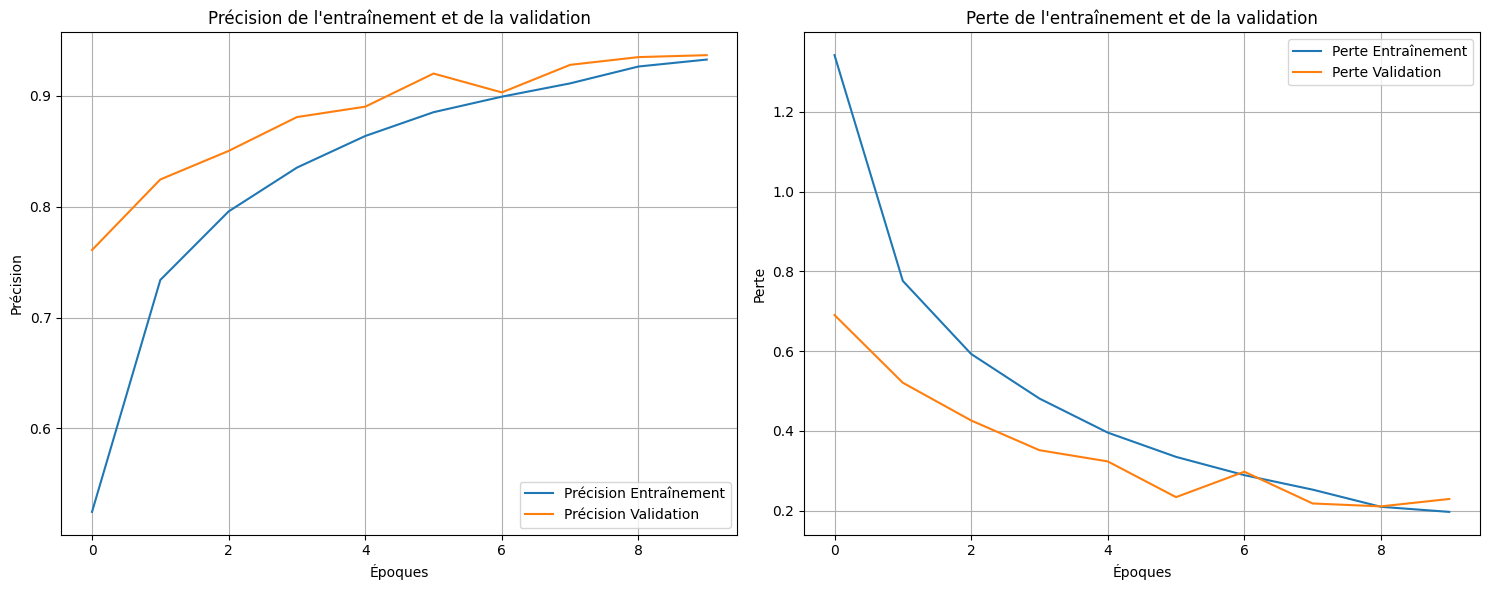

In [7]:
import matplotlib.pyplot as plt

# Récupération des données d'historique
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

# Création de la figure graphique
plt.figure(figsize=(15, 6))

# Graphique de la Précision
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Précision Entraînement')
plt.plot(epochs_range, val_acc, label='Précision Validation')
plt.legend(loc='lower right')
plt.title('Précision de l\'entraînement et de la validation')
plt.xlabel('Époques')
plt.ylabel('Précision')
plt.grid(True)

# Graphique de la Perte
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Perte Entraînement')
plt.plot(epochs_range, val_loss, label='Perte Validation')
plt.legend(loc='upper right')
plt.title('Perte de l\'entraînement et de la validation')
plt.xlabel('Époques')
plt.ylabel('Perte')
plt.grid(True)

plt.tight_layout()
plt.show()

### 5. Affichage de quelques images d'exemple du dataset
Visualisons un lot d'images avec leurs étiquettes d'origine pour vérifier le chargement des données.

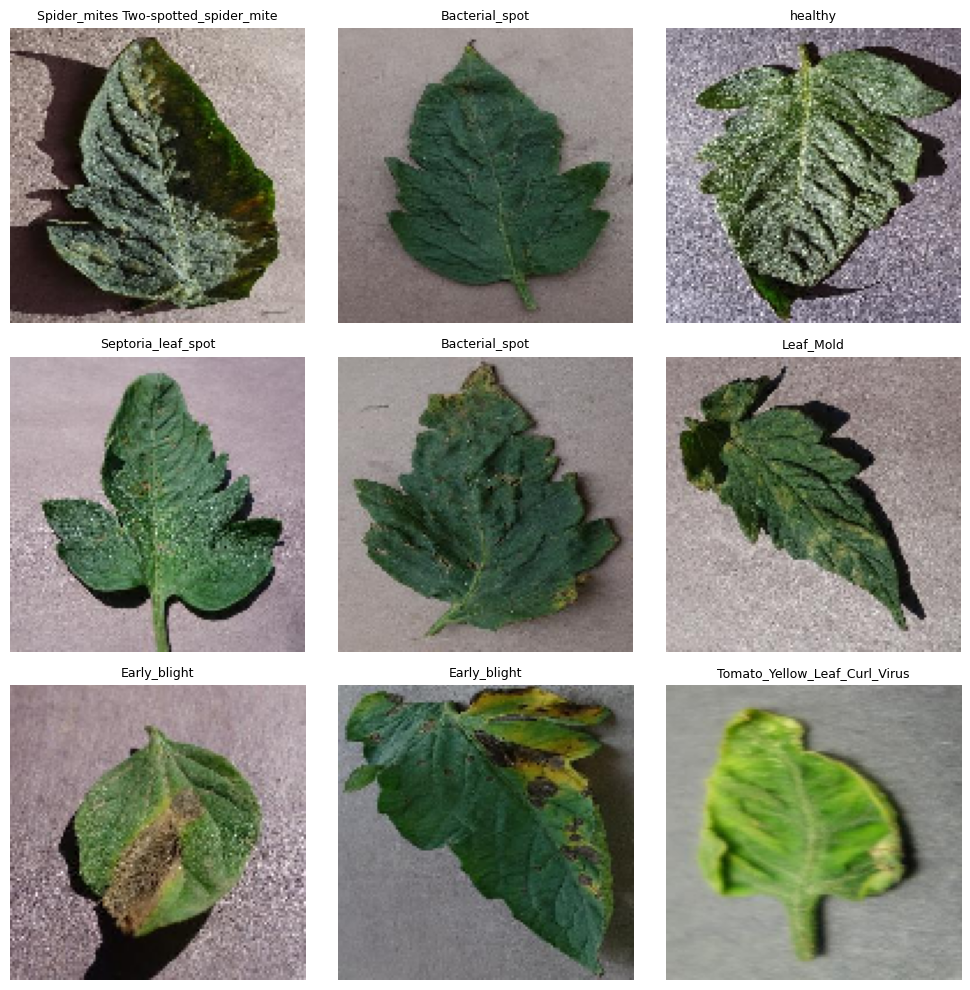

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Obtenir un batch d'images
x_batch, y_batch = next(train_generator)
class_labels = list(train_generator.class_indices.keys())

# Afficher les 9 premières images
plt.figure(figsize=(10, 10))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(x_batch[i])
    label_idx = np.argmax(y_batch[i])
    plt.title(class_labels[label_idx].split('___')[-1], fontsize=9)
    plt.axis('off')
plt.tight_layout()
plt.show()

### 6. Identification et Visualisation des Vrais/Faux Positifs et Négatifs
Puisqu'il s'agit d'une classification multi-classe (10 classes), nous définirons ces termes par rapport à une classe spécifique (ou globalement) pour générer des exemples visuels de :
- **True Positive (TP)** : La feuille a la maladie X et est prédite comme Maladie X.
- **False Positive (FP)** : La feuille saine ou ayant une autre maladie Y est prédite à tort comme Maladie X.
- **True Negative (TN)** : La feuille n'a pas la maladie X et est prédite comme n'étant pas la maladie X.
- **False Negative (FN)** : La feuille a la maladie X mais est prédite à tort comme une autre classe.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step
Analyse binaire pour la classe cible : Bacterial_spot


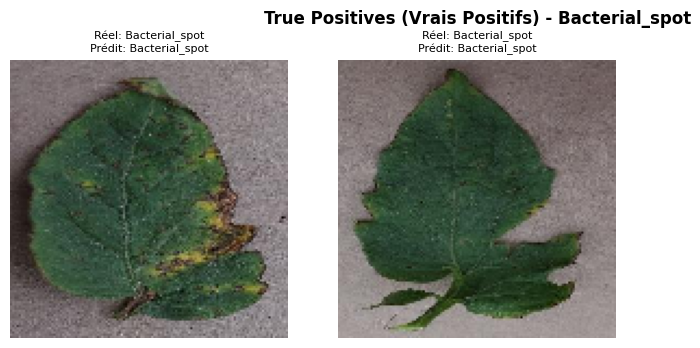

Aucun échantillon trouvé pour: False Positives (Faux Positifs) - Bacterial_spot


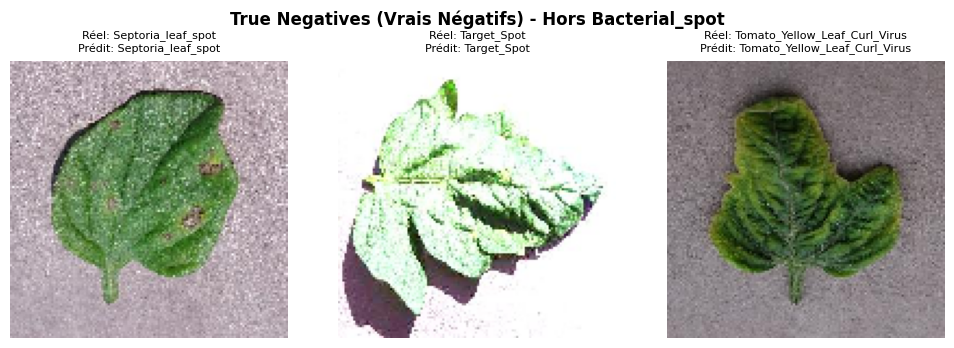

Aucun échantillon trouvé pour: False Negatives (Faux Négatifs) - Bacterial_spot


In [9]:
# Pour faire une analyse propre, prenons un lot d'images de validation
x_val, y_val = next(val_generator)
preds = model.predict(x_val)

# Classes réelles et prédites
y_true = np.argmax(y_val, axis=1)
y_pred = np.argmax(preds, axis=1)

# Choisissons la classe cible pour l'illustration (par exemple, la classe 0)
target_class_idx = 0
target_class_name = class_labels[target_class_idx].split('___')[-1]
print(f"Analyse binaire pour la classe cible : {target_class_name}")

tp_indices = []
fp_indices = []
tn_indices = []
fn_indices = []

for i in range(len(y_true)):
    actual_is_target = (y_true[i] == target_class_idx)
    pred_is_target = (y_pred[i] == target_class_idx)

    if actual_is_target and pred_is_target:
        tp_indices.append(i)
    elif not actual_is_target and pred_is_target:
        fp_indices.append(i)
    elif not actual_is_target and not pred_is_target:
        tn_indices.append(i)
    elif actual_is_target and not pred_is_target:
        fn_indices.append(i)

# Fonction d'affichage
def plot_predictions(indices, title, max_images=3):
    plt.figure(figsize=(10, 3.5))
    count = min(len(indices), max_images)
    if count == 0:
        print(f"Aucun échantillon trouvé pour: {title}")
        plt.close()
        return
    for idx, i in enumerate(indices[:count]):
        plt.subplot(1, max_images, idx + 1)
        plt.imshow(x_val[i])
        actual_name = class_labels[y_true[i]].split('___')[-1]
        pred_name = class_labels[y_pred[i]].split('___')[-1]
        plt.title(f"Réel: {actual_name}\nPrédit: {pred_name}", fontsize=8)
        plt.axis('off')
    plt.suptitle(title, fontsize=12, weight='bold')
    plt.tight_layout()
    plt.show()

# Affichage des différentes catégories
plot_predictions(tp_indices, f"True Positives (Vrais Positifs) - {target_class_name}")
plot_predictions(fp_indices, f"False Positives (Faux Positifs) - {target_class_name}")
plot_predictions(tn_indices, f"True Negatives (Vrais Négatifs) - Hors {target_class_name}")
plot_predictions(fn_indices, f"False Negatives (Faux Négatifs) - {target_class_name}")

### 7. Analyse étendue pour trouver des exemples de TP, FP, TN, et FN
Pour garantir que nous trouvons des erreurs de prédictions (Faux Positifs et Faux Négatifs), nous allons charger un échantillon plus grand du jeu de validation.

Analyse étendue sur 192 images pour la classe : Bacterial_spot



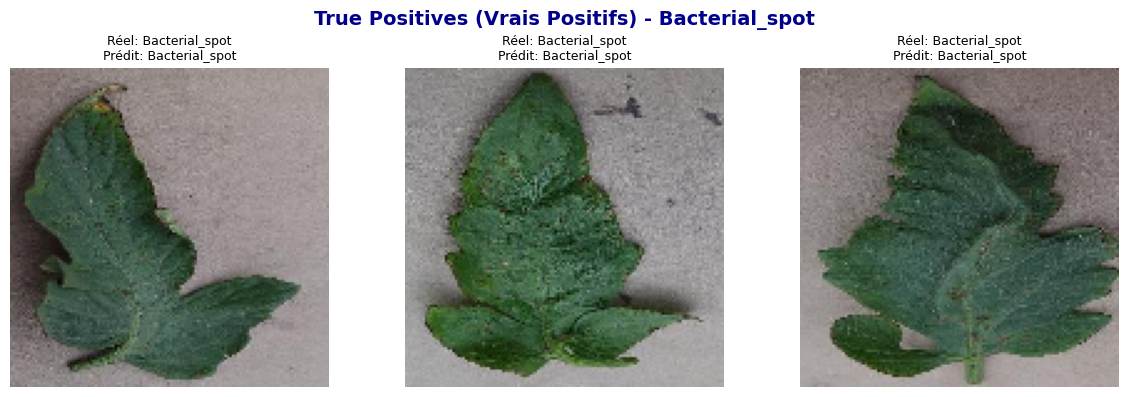

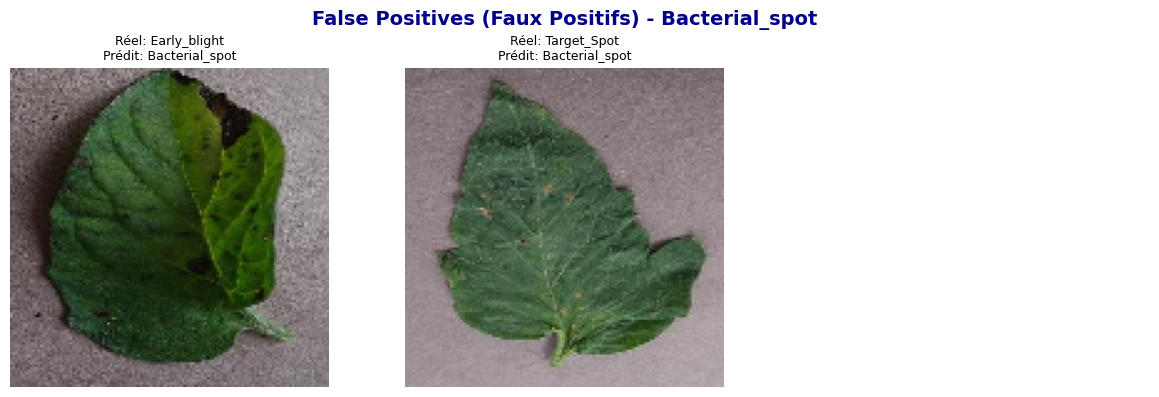

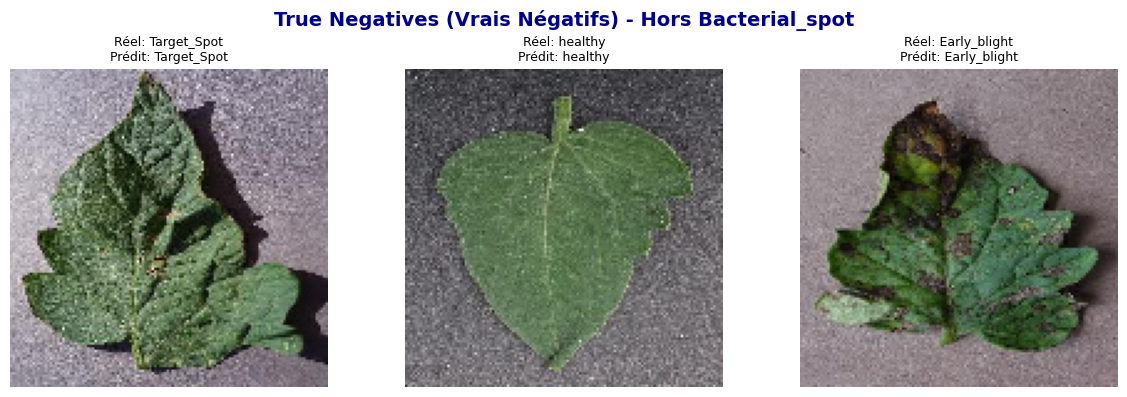

[INFO] Aucun échantillon trouvé pour la catégorie : False Negatives (Faux Négatifs) - Bacterial_spot


In [10]:
import numpy as np
import matplotlib.pyplot as plt

# Charger plusieurs lots pour avoir environ 200 images
x_large_val = []
y_large_val = []

for _ in range(6):  # 6 * 32 = 192 images
    images, labels = next(val_generator)
    x_large_val.append(images)
    y_large_val.append(labels)

x_large_val = np.vstack(x_large_val)
y_large_val = np.vstack(y_large_val)

# Prédictions
preds_large = model.predict(x_large_val, verbose=0)
y_true_large = np.argmax(y_large_val, axis=1)
y_pred_large = np.argmax(preds_large, axis=1)

# Classe cible (on peut garder la même ou en tester une autre)
target_class_idx = 0
target_class_name = class_labels[target_class_idx].split('___')[-1]
print(f"Analyse étendue sur {len(y_true_large)} images pour la classe : {target_class_name}\n")

tp_list, fp_list, tn_list, fn_list = [], [], [], []

for i in range(len(y_true_large)):
    actual_is_target = (y_true_large[i] == target_class_idx)
    pred_is_target = (y_pred_large[i] == target_class_idx)

    if actual_is_target and pred_is_target:
        tp_list.append(i)
    elif not actual_is_target and pred_is_target:
        fp_list.append(i)
    elif not actual_is_target and not pred_is_target:
        tn_list.append(i)
    elif actual_is_target and not pred_is_target:
        fn_list.append(i)

# Fonction d'affichage améliorée
def plot_grid(indices, title, max_images=3):
    if len(indices) == 0:
        print(f"[INFO] Aucun échantillon trouvé pour la catégorie : {title}")
        return

    count = min(len(indices), max_images)
    fig, axes = plt.subplots(1, max_images, figsize=(12, 4))
    fig.suptitle(title, fontsize=14, weight='bold', color='darkblue')

    # Si un seul axe est retourné, le mettre dans une liste
    if max_images == 1:
        axes = [axes]

    for idx in range(max_images):
        ax = axes[idx]
        if idx < len(indices):
            img_idx = indices[idx]
            ax.imshow(x_large_val[img_idx])
            actual_lbl = class_labels[y_true_large[img_idx]].split('___')[-1]
            pred_lbl = class_labels[y_pred_large[img_idx]].split('___')[-1]
            ax.set_title(f"Réel: {actual_lbl}\nPrédit: {pred_lbl}", fontsize=9)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# Affichage des 4 cas de figure
plot_grid(tp_list, f"True Positives (Vrais Positifs) - {target_class_name}")
plot_grid(fp_list, f"False Positives (Faux Positifs) - {target_class_name}")
plot_grid(tn_list, f"True Negatives (Vrais Négatifs) - Hors {target_class_name}")
plot_grid(fn_list, f"False Negatives (Faux Négatifs) - {target_class_name}")

### 8. Ajout de nouvelles visualisations : Matrice de Confusion et Rapport de Classification
Pour analyser l'ensemble des 10 classes de notre modèle, nous allons générer des prédictions sur une part significative du jeu de validation, puis tracer une matrice de confusion thermique avec `seaborn`.

In [11]:
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import matplotlib.pyplot as plt

# 1. Génération des prédictions sur tout le générateur de validation (sans mélange pour l'alignement)
val_generator.reset()
y_val_all = []
y_pred_all = []

# Parcourir tout le générateur pour récupérer les vraies étiquettes et les prédictions
for i in range(len(val_generator)):
    x, y = next(val_generator)
    preds = model.predict(x, verbose=0)
    y_val_all.extend(np.argmax(y, axis=1))
    y_pred_all.extend(np.argmax(preds, axis=1))

y_val_all = np.array(y_val_all)
y_pred_all = np.array(y_pred_all)

# Noms raccourcis des classes pour l'affichage graphique
short_class_names = [label.split('___')[-1] for label in class_labels]

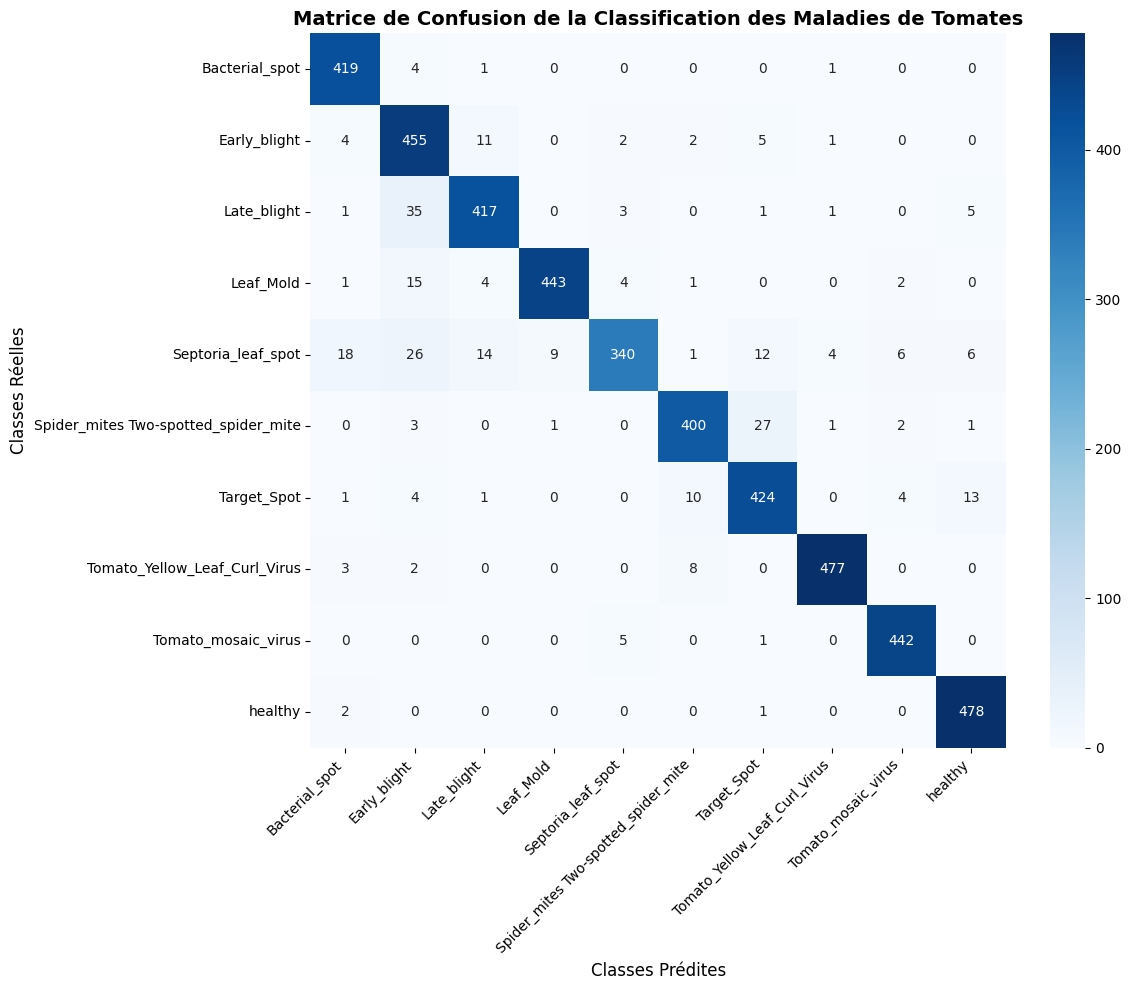

In [12]:
# 2. Tracer la Matrice de Confusion
cm = confusion_matrix(y_val_all, y_pred_all)

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=short_class_names,
            yticklabels=short_class_names)
plt.title('Matrice de Confusion de la Classification des Maladies de Tomates', fontsize=14, weight='bold')
plt.ylabel('Classes Réelles', fontsize=12)
plt.xlabel('Classes Prédites', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
# 3. Affichage du rapport complet de classification
print("Rapport de Classification Détaillé :\n")
print(classification_report(y_val_all, y_pred_all, target_names=short_class_names))

Rapport de Classification Détaillé :

                                      precision    recall  f1-score   support

                      Bacterial_spot       0.93      0.99      0.96       425
                        Early_blight       0.84      0.95      0.89       480
                         Late_blight       0.93      0.90      0.92       463
                           Leaf_Mold       0.98      0.94      0.96       470
                  Septoria_leaf_spot       0.96      0.78      0.86       436
Spider_mites Two-spotted_spider_mite       0.95      0.92      0.93       435
                         Target_Spot       0.90      0.93      0.91       457
       Tomato_Yellow_Leaf_Curl_Virus       0.98      0.97      0.98       490
                 Tomato_mosaic_virus       0.97      0.99      0.98       448
                             healthy       0.95      0.99      0.97       481

                            accuracy                           0.94      4585
                        